# T3 — Modelos de predicción de demandas sísmicas (ln MIDR y Vb/W)

Curso **Aplicaciones de IA en Estructuras** (UPC) · Grupo: Díaz, De la Cruz, Valdez, Mamani, Cueva.

Este notebook aplica el plan de ML del Informe T2 (sección 3) al dataset real de la campaña NLTHA:

1. Carga `data/dataset_sismico_peru.csv` (unión de los CSV de cada integrante) y excluye las fallas numéricas.
2. Entrena **5 familias de modelos** por target: Ridge log-lineal (línea base), Random Forest, XGBoost, LightGBM y red neuronal MLP.
3. Ajusta hiperparámetros con **búsqueda aleatoria + GroupKFold(5) por evento** (`eqid`) solo dentro de train.
4. Evalúa una sola vez en la **prueba retenida** (eventos que el modelo nunca vio).
5. Deriva el cumplimiento de deriva (0.007 y 0.00875) a partir del MIDR predicho y evalúa la clase "no cumple".
6. Interpreta el mejor modelo con **SHAP**.

Los criterios de aceptación se fijaron en el T2 **antes** de ver resultados.

In [1]:
import warnings, time, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import loguniform, randint, uniform
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import GroupKFold, RandomizedSearchCV, cross_val_predict
from sklearn.metrics import r2_score, mean_squared_error, confusion_matrix, precision_score, recall_score, f1_score
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
import shap

warnings.filterwarnings("ignore")
SEMILLA = 2026
np.random.seed(SEMILLA)
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = RAIZ / "docs" / "figuras"
FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Datos

In [2]:
df = pd.read_csv(RAIZ / "data" / "dataset_sismico_peru.csv")
print(f"Filas totales: {len(df)} · arquetipos: {df.id_arquetipo.nunique()} de 40 · registros: {df.id_registro.nunique()} · eventos: {df.eqid.nunique()}")
print("Filas por archivo de origen:", df.archivo_origen.value_counts().to_dict())
print("Fallas numéricas (convergencia = 0):", int((df.convergencia == 0).sum()), "· colapsos:", int(df.colapso.sum()))

df = df[(df.convergencia == 1) & (df.colapso == 0)].reset_index(drop=True)
print(f"Filas para modelar: {len(df)}")

cat = pd.read_csv(RAIZ / "data" / "catalogo_arquetipos.csv")
faltan = sorted(set(cat.id_arquetipo) - set(df.id_arquetipo))
print("Arquetipos sin resultados (no ejecutados):", faltan)
display(df.groupby(["particion", "sistema"]).size().unstack())

Filas totales: 1422 · arquetipos: 35 de 40 · registros: 22 · eventos: 14
Filas por archivo de origen: {'resultados_mitad1_delacruz.csv': 928, 'resultados_mitad2_B_guido.csv': 324, 'resultados_mitad2_A_paulino.csv': 93, 'resultados_mitad2_C_felix.csv': 77}
Fallas numéricas (convergencia = 0): 12 · colapsos: 0
Filas para modelar: 1410
Arquetipos sin resultados (no ejecutados): ['DUA-04', 'DUA-10', 'MUR-01', 'MUR-03', 'POR-06']


sistema,dual,muros,porticos
particion,,,
test,108,97,116
train,358,327,404


In [3]:
cobertura = df.groupby("id_arquetipo").size()
print(f"Arquetipos completos (66 casos): {(cobertura == 66).sum()} · mediana de casos por arquetipo: {cobertura.median():.0f}")
print("Casos por registro (id_registro):")
print(df.groupby("id_registro").size().sort_values().to_string())

Arquetipos completos (66 casos): 3 · mediana de casos por arquetipo: 45
Casos por registro (id_registro):
id_registro
1485     12
1148     15
1158     15
1244     15
1633     15
1787     15
1602     45
900      72
1116     72
953      74
960      75
1111     75
767      75
829      75
848      75
752      78
725      96
721      98
169     101
68      102
174     105
125     105


### Variables

Se usan las 31 variables de entrada del diccionario (docs/03) **menos** dos:
- `Z`: constante (todos los arquetipos en Z4), no aporta información.
- `factor_escala`: es una decisión del analista, no una propiedad del sismo; su efecto ya está en las IM escaladas (nota del docs/03).

Quedan **29 variables**. Para Ridge y la MLP se aplica ln a las variables de escala (IM, peso, área, distancias) y estandarización; los árboles usan las variables tal cual.

In [4]:
NUM = ["R0", "n_pisos", "H_m", "h_piso_m", "area_planta_m2", "T1_s", "W_kN", "densidad_muros_pct", "fc_kgcm2",
       "U", "S", "TP_s", "TL_s", "Ts_s", "C_T1", "Vest_W", "Sa_dis_R1_g",
       "PGA_g", "PGV_ms", "Sa_T1_g", "Sa_avg_g", "Arias_ms", "D5_95_s", "HI_m", "ASI_gs",
       "Mw", "Rrup_km", "Vs30_est_ms"]
CAT = ["sistema"]
LOGV = ["area_planta_m2", "T1_s", "W_kN", "Sa_dis_R1_g", "PGA_g", "PGV_ms", "Sa_T1_g", "Sa_avg_g",
        "Arias_ms", "D5_95_s", "HI_m", "ASI_gs", "Rrup_km", "Vs30_est_ms"]
LINV = [c for c in NUM if c not in LOGV]
FEATS = NUM + CAT
print(len(FEATS), "variables")

tr, te = df[df.particion == "train"].reset_index(drop=True), df[df.particion == "test"].reset_index(drop=True)
Xtr, Xte = tr[FEATS], te[FEATS]
gtr = tr.eqid.values
print(f"train: {len(tr)} casos de {tr.eqid.nunique()} eventos · test: {len(te)} casos de {te.eqid.nunique()} eventos")
assert not set(tr.eqid) & set(te.eqid), "fuga: un evento en dos particiones"

# Preprocesamiento para modelos sensibles a la escala (Ridge, MLP)
prep_esc = ColumnTransformer([
    ("log", Pipeline([("ln", FunctionTransformer(np.log)), ("sc", StandardScaler())]), LOGV),
    ("lin", StandardScaler(), LINV),
    ("cat", OneHotEncoder(drop="first"), CAT),
])
# Preprocesamiento para árboles: solo codificar el sistema
prep_arb = ColumnTransformer([("num", "passthrough", NUM), ("cat", OneHotEncoder(drop="first"), CAT)])

29 variables
train: 1089 casos de 11 eventos · test: 321 casos de 3 eventos


## 2. Modelos y búsqueda de hiperparámetros

Cada modelo se ajusta con `RandomizedSearchCV` y **GroupKFold(5) por evento** solo sobre train. La métrica de selección es el RMSE.

> Desviaciones respecto del plan T2 (por tiempo de cómputo y tamaño del dataset): 20 combinaciones por modelo en vez de 30, validación cruzada simple (no anidada) y la MLP en scikit-learn en vez de PyTorch.

In [5]:
def modelos():
    return {
        "Ridge (base)": (Pipeline([("p", prep_esc), ("m", Ridge())]),
                         {"m__alpha": loguniform(1e-3, 1e3)}),
        "Random Forest": (Pipeline([("p", prep_arb), ("m", RandomForestRegressor(random_state=SEMILLA, n_jobs=-1))]),
                          {"m__n_estimators": randint(200, 600), "m__max_depth": [None, 8, 12, 16, 24],
                           "m__min_samples_leaf": randint(1, 8), "m__max_features": uniform(0.3, 0.6)}),
        "XGBoost": (Pipeline([("p", prep_arb), ("m", XGBRegressor(random_state=SEMILLA, n_jobs=-1, verbosity=0))]),
                    {"m__n_estimators": randint(200, 900), "m__learning_rate": loguniform(0.01, 0.2),
                     "m__max_depth": randint(2, 7), "m__subsample": uniform(0.6, 0.4),
                     "m__colsample_bytree": uniform(0.5, 0.5), "m__reg_lambda": loguniform(1e-2, 10)}),
        "LightGBM": (Pipeline([("p", prep_arb), ("m", LGBMRegressor(random_state=SEMILLA, n_jobs=-1, verbose=-1))]),
                     {"m__n_estimators": randint(200, 900), "m__learning_rate": loguniform(0.01, 0.2),
                      "m__num_leaves": randint(8, 48), "m__min_child_samples": randint(5, 40),
                      "m__subsample": uniform(0.6, 0.4), "m__subsample_freq": [1],
                      "m__colsample_bytree": uniform(0.5, 0.5), "m__reg_lambda": loguniform(1e-2, 10)}),
        "Red neuronal MLP": (TransformedTargetRegressor(
                                regressor=Pipeline([("p", prep_esc), ("m", MLPRegressor(max_iter=3000, early_stopping=True,
                                                    validation_fraction=0.15, n_iter_no_change=40, random_state=SEMILLA))]),
                                transformer=StandardScaler()),
                             {"regressor__m__hidden_layer_sizes": [(32,), (64,), (64, 32), (128, 64), (64, 64, 32)],
                              "regressor__m__alpha": loguniform(1e-5, 1e-1),
                              "regressor__m__learning_rate_init": loguniform(1e-4, 1e-2),
                              "regressor__m__activation": ["relu", "tanh"]}),
    }

def ajustar(target, n_iter=20):
    ytr = tr[target].values
    cv = GroupKFold(n_splits=5)
    out = {}
    for nombre, (est, grid) in modelos().items():
        t0 = time.time()
        bs = RandomizedSearchCV(est, grid, n_iter=n_iter if len(grid) > 1 else 15, cv=cv,
                                scoring="neg_root_mean_squared_error", random_state=SEMILLA, n_jobs=1, refit=True)
        bs.fit(Xtr, ytr, groups=gtr)
        # predicciones fuera de fold con los mejores hiperparámetros (para R² y RMSE de CV)
        oof = cross_val_predict(bs.best_estimator_, Xtr, ytr, groups=gtr, cv=cv)
        out[nombre] = {"modelo": bs.best_estimator_, "oof": oof, "pred_te": bs.best_estimator_.predict(Xte),
                       "params": bs.best_params_, "seg": time.time() - t0}
        print(f"  {nombre:<18} CV RMSE={-bs.best_score_:.3f}  ({out[nombre]['seg']:.0f} s)")
    return out

## 3. Target 1 — ln(MIDR)

In [6]:
print("Ajustando modelos para ln(MIDR)...")
res_midr = ajustar("ln_MIDR")

Ajustando modelos para ln(MIDR)...


  Ridge (base)       CV RMSE=0.273  (1 s)


  Random Forest      CV RMSE=0.277  (101 s)


  XGBoost            CV RMSE=0.269  (29 s)


  LightGBM           CV RMSE=0.273  (30 s)


  Red neuronal MLP   CV RMSE=0.295  (82 s)


In [7]:
def tabla_metricas(res, target, escala_exp=False):
    ytr, yte = tr[target].values, te[target].values
    filas = []
    for n, r in res.items():
        f = {"Modelo": n,
             "R² CV": r2_score(ytr, r["oof"]), "RMSE CV": mean_squared_error(ytr, r["oof"]) ** 0.5,
             "R² test": r2_score(yte, r["pred_te"]), "RMSE test": mean_squared_error(yte, r["pred_te"]) ** 0.5}
        if escala_exp:
            f["MAPE test MIDR (%)"] = 100 * np.mean(np.abs(np.exp(r["pred_te"]) - np.exp(yte)) / np.exp(yte))
        else:
            f["MAPE test (%)"] = 100 * np.mean(np.abs(r["pred_te"] - yte) / yte)
        f["Brecha R² (CV − test)"] = f["R² CV"] - f["R² test"]
        filas.append(f)
    return pd.DataFrame(filas).set_index("Modelo").round(3)

t_midr = tabla_metricas(res_midr, "ln_MIDR", escala_exp=True)
t_midr = t_midr.rename(columns={"RMSE CV": "σln CV", "RMSE test": "σln test"})
display(t_midr)

,R² CV,σln CV,R² test,σln test,MAPE test MIDR (%),Brecha R² (CV − test)
Modelo,,,,,,
Ridge (base),0.836,0.277,0.699,0.440,30.120,0.138
Random Forest,0.834,0.279,0.788,0.368,27.567,0.046
XGBoost,0.843,0.271,0.823,0.337,25.461,0.020
LightGBM,0.839,0.275,0.793,0.364,27.067,0.045
Red neuronal MLP,0.812,0.296,0.678,0.454,29.426,0.134


## 4. Target 2 — Vb/W

In [8]:
print("Ajustando modelos para Vb/W...")
res_vb = ajustar("Vb_W")
t_vb = tabla_metricas(res_vb, "Vb_W")
display(t_vb)

Ajustando modelos para Vb/W...


  Ridge (base)       CV RMSE=0.068  (1 s)


  Random Forest      CV RMSE=0.050  (101 s)


  XGBoost            CV RMSE=0.051  (29 s)


  LightGBM           CV RMSE=0.051  (32 s)


  Red neuronal MLP   CV RMSE=0.056  (57 s)


,R² CV,RMSE CV,R² test,RMSE test,MAPE test (%),Brecha R² (CV − test)
Modelo,,,,,,
Ridge (base),0.882,0.068,0.887,0.075,17.752,-0.006
Random Forest,0.936,0.050,0.945,0.053,12.424,-0.009
XGBoost,0.934,0.051,0.944,0.053,12.985,-0.009
LightGBM,0.933,0.051,0.944,0.053,13.207,-0.011
Red neuronal MLP,0.921,0.056,0.915,0.066,13.118,0.006


## 5. Selección del modelo y criterios de aceptación

El mejor modelo se elige por **RMSE de validación cruzada** (no por el test, para no sesgar la elección).

In [9]:
mejor_midr = t_midr["σln CV"].idxmin()
mejor_vb = t_vb["RMSE CV"].idxmin()
print("Mejor para ln(MIDR):", mejor_midr, "· mejor para Vb/W:", mejor_vb)

UMBRALES = {"0.007": 0.007, "0.00875": 0.00875}
def cumplimiento(pred_ln, y_ln):
    filas = []
    for etq, lim in UMBRALES.items():
        real_nc = np.exp(y_ln) > lim       # positivo = NO cumple (clase de seguridad)
        pred_nc = np.exp(pred_ln) > lim
        cm = confusion_matrix(real_nc, pred_nc, labels=[False, True])
        filas.append({"Límite": etq, "Casos no cumple (real)": int(real_nc.sum()),
                      "Precisión no cumple": precision_score(real_nc, pred_nc),
                      "Recall no cumple": recall_score(real_nc, pred_nc),
                      "F1 no cumple": f1_score(real_nc, pred_nc),
                      "Falsos 'cumple' (inseguros)": int(cm[1, 0]), "Falsos 'no cumple'": int(cm[0, 1])})
    return pd.DataFrame(filas).set_index("Límite").round(3)

t_cump = cumplimiento(res_midr[mejor_midr]["pred_te"], te.ln_MIDR.values)
display(t_cump)

fm = t_midr.loc[mejor_midr]
criterios = pd.DataFrame([
    ["R² test ln(MIDR) ≥ 0.85", f"{fm['R² test']:.3f}", fm["R² test"] >= 0.85],
    ["σln test ≤ 0.35", f"{fm['σln test']:.3f}", fm["σln test"] <= 0.35],
    ["F1 'no cumple' (0.007) ≥ 0.85", f"{t_cump.loc['0.007','F1 no cumple']:.3f}", t_cump.loc["0.007", "F1 no cumple"] >= 0.85],
    ["Brecha R² CV − test ≤ 0.05", f"{fm['Brecha R² (CV − test)']:.3f}", fm["Brecha R² (CV − test)"] <= 0.05],
    ["Supera a Ridge (σln CV)", f"{fm['σln CV']:.3f} vs {t_midr.loc['Ridge (base)','σln CV']:.3f}",
     fm["σln CV"] < t_midr.loc["Ridge (base)", "σln CV"]],
], columns=["Criterio (fijado en T2)", "Valor", "Cumple"])
display(criterios)

Mejor para ln(MIDR): XGBoost · mejor para Vb/W: Random Forest


,Casos no cumple (real),Precisión no cumple,Recall no cumple,F1 no cumple,Falsos 'cumple' (inseguros),Falsos 'no cumple'
Límite,,,,,,
0.007,151,0.909,0.861,0.884,21,13
0.00875,119,0.865,0.756,0.807,29,14


,Criterio (fijado en T2),Valor,Cumple
0,R² test ln(MIDR) ≥ 0.85,0.823,False
1,σln test ≤ 0.35,0.337,True
2,F1 'no cumple' (0.007) ≥ 0.85,0.884,True
3,Brecha R² CV − test ≤ 0.05,0.020,True
4,Supera a Ridge (σln CV),0.271 vs 0.277,True


## 6. Figuras

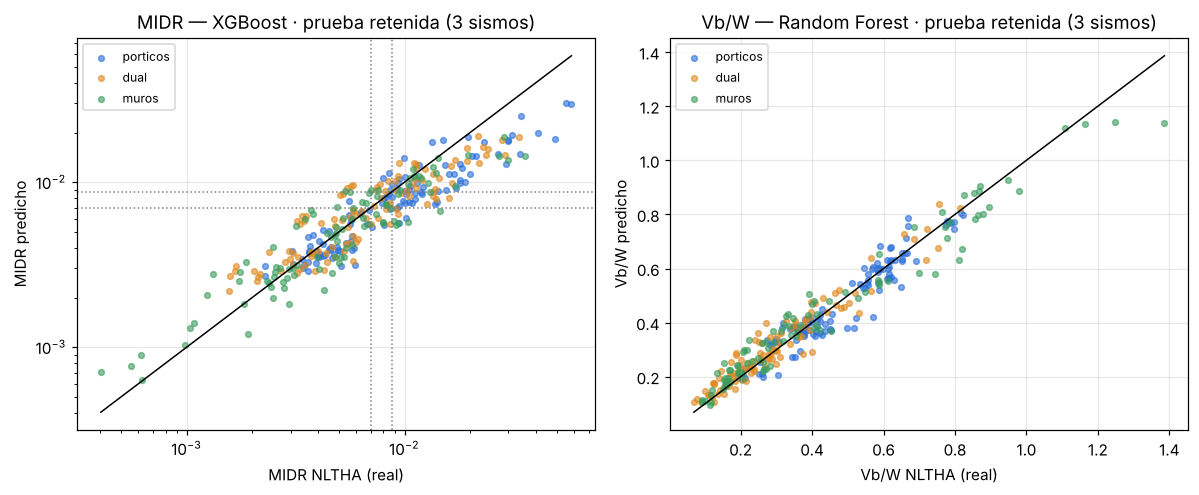

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.6))
for a, (res, nom, tgt, lab) in zip(ax, [(res_midr, mejor_midr, "ln_MIDR", "MIDR"), (res_vb, mejor_vb, "Vb_W", "Vb/W")]):
    y, p = te[tgt].values, res[nom]["pred_te"]
    if tgt == "ln_MIDR":
        y, p = np.exp(y), np.exp(p)
        a.set_xscale("log"); a.set_yscale("log")
        for lim in (0.007, 0.00875):
            a.axvline(lim, color="gray", ls=":", lw=1); a.axhline(lim, color="gray", ls=":", lw=1)
    for s, c in zip(["porticos", "dual", "muros"], ["#2a6fdb", "#e08a1e", "#3a9d5d"]):
        m = te.sistema.values == s
        a.scatter(y[m], p[m], s=14, alpha=0.6, color=c, label=s)
    lo, hi = min(y.min(), p.min()), max(y.max(), p.max())
    a.plot([lo, hi], [lo, hi], "k-", lw=1)
    a.set_xlabel(f"{lab} NLTHA (real)"); a.set_ylabel(f"{lab} predicho")
    a.set_title(f"{lab} — {nom} · prueba retenida (3 sismos)")
    a.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "t3_pred_vs_real.png", dpi=150, bbox_inches="tight"); plt.show()

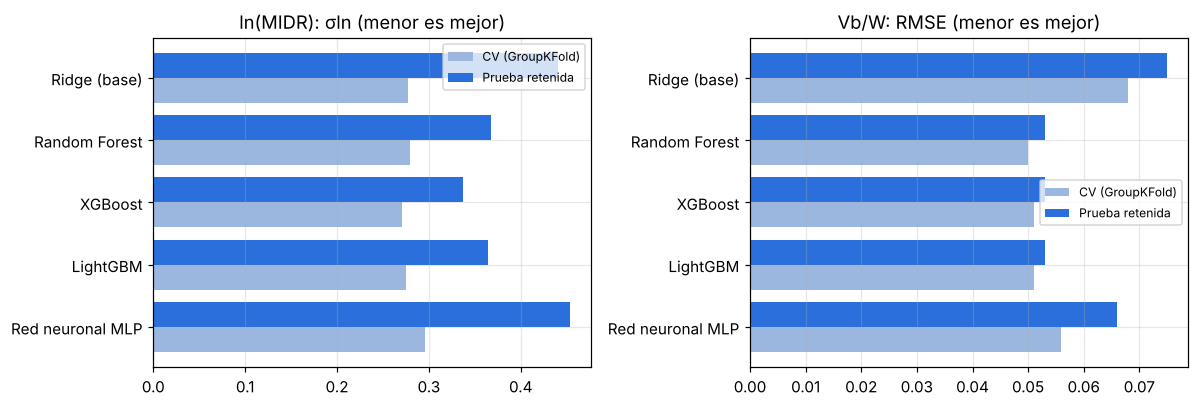

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for a, (t, col, tit) in zip(ax, [(t_midr, "σln", "ln(MIDR): σln"), (t_vb, "RMSE", "Vb/W: RMSE")]):
    idx = np.arange(len(t))
    a.barh(idx + 0.2, t[f"{col} CV"], 0.4, label="CV (GroupKFold)", color="#9bb7e0")
    a.barh(idx - 0.2, t[f"{col} test"], 0.4, label="Prueba retenida", color="#2a6fdb")
    a.set_yticks(idx, t.index); a.invert_yaxis(); a.set_title(tit + " (menor es mejor)"); a.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "t3_comparacion_modelos.png", dpi=150, bbox_inches="tight"); plt.show()

## 7. Interpretación con SHAP

Se usa el mejor modelo de árboles para cada target (TreeExplainer). Las variables más influyentes deberían ser las de intensidad (Sa(T1), Sa_avg) y el periodo, como anticipó el EDA del T2.

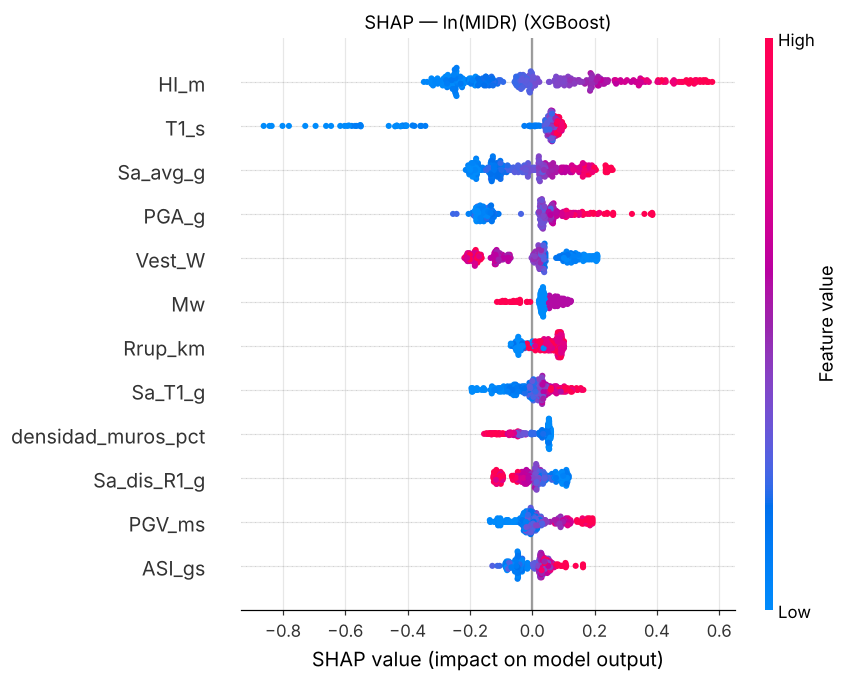

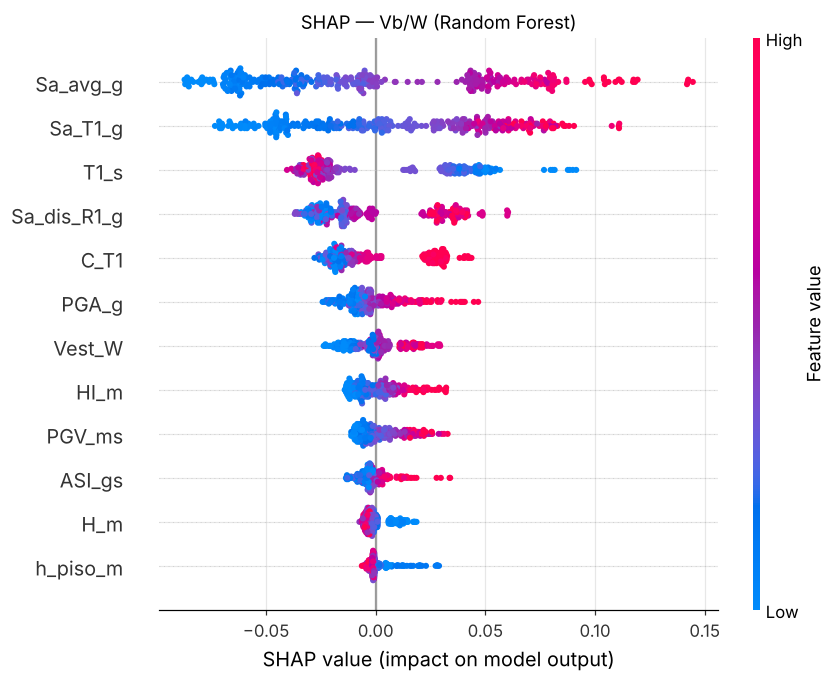

,ln(MIDR) · XGBoost,Vb/W · Random Forest
0,HI_m,Sa_avg_g
1,T1_s,Sa_T1_g
2,Sa_avg_g,T1_s
3,PGA_g,Sa_dis_R1_g
4,Vest_W,C_T1
5,Mw,PGA_g
6,Rrup_km,Vest_W
7,Sa_T1_g,HI_m


In [12]:
def shap_arbol(res, t, target, archivo):
    arboles = [n for n in ["Random Forest", "XGBoost", "LightGBM"]]
    nom = min(arboles, key=lambda n: t.loc[n].iloc[1])
    pipe = res[nom]["modelo"]
    Xt = pipe.named_steps["p"].transform(Xte)
    nombres = NUM + [f"sistema_{c}" for c in pipe.named_steps["p"].named_transformers_["cat"].categories_[0][1:]]
    sv = shap.TreeExplainer(pipe.named_steps["m"]).shap_values(Xt)
    imp = pd.Series(np.abs(sv).mean(0), index=nombres).sort_values(ascending=False)
    plt.figure()
    shap.summary_plot(sv, pd.DataFrame(Xt, columns=nombres), max_display=12, show=False)
    plt.title(f"SHAP — {target} ({nom})"); plt.tight_layout()
    plt.savefig(FIG / archivo, dpi=150, bbox_inches="tight"); plt.show()
    return nom, imp

nom_s1, imp_midr = shap_arbol(res_midr, t_midr, "ln(MIDR)", "t3_shap_midr.png")
nom_s2, imp_vb = shap_arbol(res_vb, t_vb, "Vb/W", "t3_shap_vbw.png")
display(pd.DataFrame({f"ln(MIDR) · {nom_s1}": imp_midr.head(8).index, f"Vb/W · {nom_s2}": imp_vb.head(8).index}))

## 8. Error por nivel de intensidad y por sistema (mejor modelo de ln MIDR)

In [13]:
te_res = te.assign(err=res_midr[mejor_midr]["pred_te"] - te.ln_MIDR)
display(te_res.groupby("nivel_escala").err.agg(sesgo="mean", sigma_ln="std", n="size").round(3))
display(te_res.groupby("sistema").err.agg(sesgo="mean", sigma_ln="std", n="size").round(3))

,sesgo,sigma_ln,n
nivel_escala,,,
0.5,-0.031,0.283,109
1.0,-0.120,0.316,108
1.5,-0.136,0.362,104


,sesgo,sigma_ln,n
sistema,,,
dual,-0.030,0.325,108
muros,-0.045,0.343,97
porticos,-0.197,0.280,116


## 9. Exportar resultados

In [14]:
salida = RAIZ / "data" / "resultados_modelos_t3.json"
json.dump({
    "n_modelado": int(len(df)), "n_train": int(len(tr)), "n_test": int(len(te)),
    "arquetipos_sin_datos": faltan,
    "metricas_ln_MIDR": t_midr.reset_index().to_dict(orient="records"),
    "metricas_Vb_W": t_vb.reset_index().to_dict(orient="records"),
    "cumplimiento": t_cump.reset_index().to_dict(orient="records"),
    "criterios": criterios.astype(str).to_dict(orient="records"),
    "mejor_ln_MIDR": mejor_midr, "mejor_Vb_W": mejor_vb,
    "hiperparametros": {"ln_MIDR": {k: {p: (v if isinstance(v, (int, float, str)) else str(v)) for p, v in r["params"].items()} for k, r in res_midr.items()},
                         "Vb_W": {k: {p: (v if isinstance(v, (int, float, str)) else str(v)) for p, v in r["params"].items()} for k, r in res_vb.items()}},
    "shap_top_ln_MIDR": imp_midr.head(8).round(4).to_dict(), "shap_top_Vb_W": imp_vb.head(8).round(4).to_dict(),
}, open(salida, "w"), indent=2, ensure_ascii=False, default=str)
print("Guardado:", salida.relative_to(RAIZ))

Guardado: data/resultados_modelos_t3.json
